# User-defined intensity model (advanced)

FRAP allows us to define an intensity model instead of the default dust radiative transfer model (Sierra & Lizano 2020).
To demonstrate this, here we fit the HD 169142 Band 3 and Band 6 visibilities directly with a radial intensity normalization and spectral index.

We assume a power-law spectrum at each radius:

$$I_\nu(R) = I_0(R)\left(\frac{\nu}{\nu_0}\right)^{\alpha(R)}, \qquad \nu_0 = 230\,{\rm GHz}.$$

Both $\log_{10} I_0(R)$ and $\alpha(R)$ are free radial profiles modeled with Gaussian processes.

(If you set this to I = I_0 and apply it to single band observations, this is essentially auto-diff version of [frankenstein](https://discsim.github.io/frank/))

## 1. Load the data

In [1]:
import frap
import pickle
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

bands = ['band3', 'band6']
files = {'band3': 'HD169142_band3.pkl', 
         'band6': 'HD169142_band6.pkl'}

obs = {}
for band in bands:
    with open(files[band], 'rb') as f:
        obs[band] = pickle.load(f)

## 2. Define the intensity function

A user-defined intensity function takes `(obs, incl, params)` and returns intensity in cgs units (`erg s^-1 cm^-2 Hz^-1 sr^-1`). The observation frequency is available as `obs.nu`.

In [2]:

def powerlaw_intensity(obs, incl, params):

    nu0 = 230e9  # Hz

    I0 = 10**params['log10_I0']
    alpha = params['alpha']
    
    return I0 * (obs.nu / nu0)**alpha

## 3. Set up the model

Now you should define the parameters that you use in the defined model.

In [3]:
disk = frap.model(incl=6.28, 
                  pa=6.3, 
                  r_out=1.3, 
                  N_GP=130, 
                  intensity_function=powerlaw_intensity,  # here you can set your own model!
                  jitter=1e-6)

disk.set_parameter('log10_I0',
                   bounds=(-18.0, -10.0), 
                   lengthscale=0.03)

disk.set_parameter('alpha',
                   bounds=(0.0, 4.0), 
                   lengthscale=0.03)

f_s = {'band3': 0.025, 'band6': 0.05}

for band in bands:
    disk.set_visibility(band=band, 
                        q=obs[band]['q'],
                        V=obs[band]['V'], 
                        s=obs[band]['s'], 
                        nu=obs[band]['nu'], 
                        Nch=obs[band]['Nch'], 
                        f_s=f_s[band], 
                        f_mean=1.0)

disk.summary()

FRAP model summary

[Model]
  Inclination      : 6.280 deg
  Position angle   : 6.300 deg
  Radial grid      : FB, N=130, r_out=1.3 arcsec
  Radial range     : 0.007611 - 1.29 arcsec
  Jitter           : 1e-06
  GP hyperparams   : fixed
  Flux uncertainty : True

[Emission]
  Intensity  : powerlaw_intensity
  Visibility : None
  Opacity    : not configured

[Parameters]  2 free, 0 fixed, 260 latent variables
  log10_I0          : GP, bounds=(-18, -10), lengthscale=0.03 arcsec
  alpha             : GP, bounds=(0, 4), lengthscale=0.03 arcsec

[Observations]
  Band   Type        Nch  Frequency [GHz]       Ndata
  band3  visibility    2  91.565-103.565          257
  band6  visibility    4  218.096-234.096         948

[User-defined intensity function]
  Signature: intensity_function(obs, incl, f_latents, output_tau)

  Arguments:
    incl       : inclination [rad]
    f_latents  : parameter dictionary (see [Parameters])
    output_tau : bool (True: return optical depth)

  Accessible obse

'FRAP model summary\n==================\n\n[Model]\n  Inclination      : 6.280 deg\n  Position angle   : 6.300 deg\n  Radial grid      : FB, N=130, r_out=1.3 arcsec\n  Radial range     : 0.007611 - 1.29 arcsec\n  Jitter           : 1e-06\n  GP hyperparams   : fixed\n  Flux uncertainty : True\n\n[Emission]\n  Intensity  : powerlaw_intensity\n  Visibility : None\n  Opacity    : not configured\n\n[Parameters]  2 free, 0 fixed, 260 latent variables\n  log10_I0          : GP, bounds=(-18, -10), lengthscale=0.03 arcsec\n  alpha             : GP, bounds=(0, 4), lengthscale=0.03 arcsec\n\n[Observations]\n  Band   Type        Nch  Frequency [GHz]       Ndata\n  band3  visibility    2  91.565-103.565          257\n  band6  visibility    4  218.096-234.096         948\n\n[User-defined intensity function]\n  Signature: intensity_function(obs, incl, f_latents, output_tau)\n\n  Arguments:\n    incl       : inclination [rad]\n    f_latents  : parameter dictionary (see [Parameters])\n    output_tau : 

## 4. Run MCMC

In [8]:
inference = frap.inference(disk)
result = inference.MCMC(num_warmup=1000, num_samples=1000, num_chains=1, seed=1)

sample: 100%|██████████████████████████| 1000/1000 [01:08<00:00, 14.61it/s, 1023 steps of size 3.24e-02. acc. prob=0.93]


                       mean       std    median      5.0%     95.0%     n_eff     r_hat
     g_alpha_z[0]     -1.96      0.14     -1.95     -2.16     -1.72    908.25      1.00
     g_alpha_z[1]      0.25      0.88      0.27     -1.13      1.65    564.49      1.00
     g_alpha_z[2]      0.03      0.97      0.01     -1.52      1.70    503.26      1.01
     g_alpha_z[3]     -0.15      0.92     -0.15     -1.74      1.30    536.74      1.00
     g_alpha_z[4]     -0.28      0.93     -0.28     -1.83      1.20    625.36      1.00
     g_alpha_z[5]     -0.46      0.91     -0.43     -2.03      0.90    666.51      1.00
     g_alpha_z[6]     -0.47      0.89     -0.47     -1.81      1.10    585.26      1.01
     g_alpha_z[7]     -0.38      0.92     -0.37     -1.82      1.09    512.65      1.00
     g_alpha_z[8]     -0.30      0.92     -0.31     -1.87      1.17    510.42      1.00
     g_alpha_z[9]     -0.14      0.88     -0.13     -1.60      1.30    580.29      1.00
    g_alpha_z[10]     -0.11    

The results look consistent with image-based one by Macias et al. (2019)

saved keys:  dict_keys(['warmup_f', 'posterior_f', 'warmup_g', 'posterior_g'])


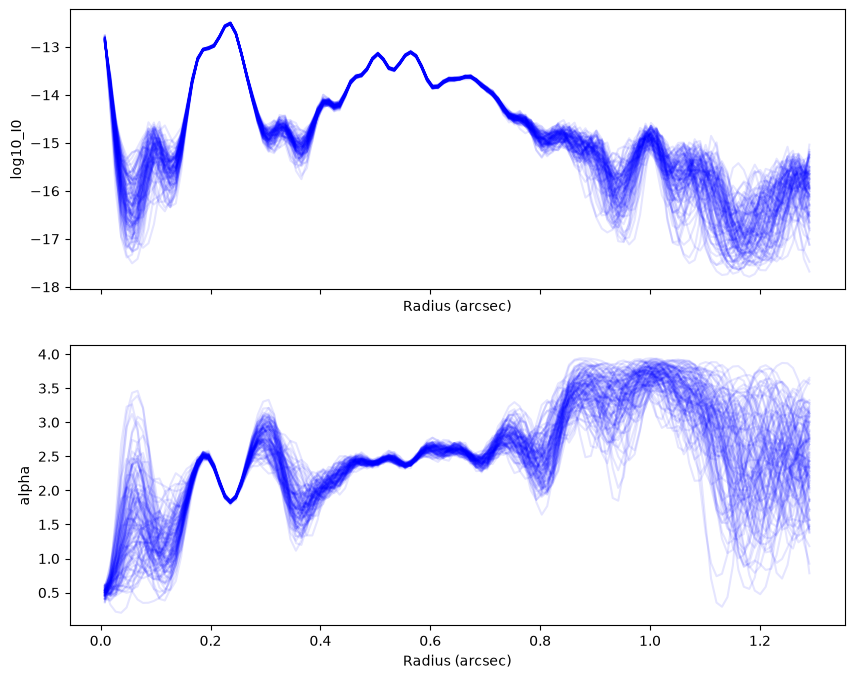

In [10]:
plotter = frap.plot( result )
plotter.sample_paths( 'posterior_f', nskip = 10, plot_kwargs = { 'alpha' : 0.1, 'color' : 'b' } )